In [1]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load

In [2]:
from numpy import cos, sin

In [3]:
def def_parametros(tipo_dados):
    if tipo_dados == 'completo':
        parametros = [
        "TIME",
        "TEMPO_SAD",
        "EVENTO",
        "HH",
        "MM",
        "SS",
        "MSS",
        "TOT",
        "ALFAG",
        "BETAG",
        "DL",
        "DM",
        "DN",
        "DF",
        "NX",
        "NY",
        "NZ",
        "P",
        "Q",
        "R",
        "PB",
        "PB1",
        "QB",
        "QB1",
        "TI",
        "T5_C",
        "TETAL",
        "FIL",
        "CID",
        "NG",
        "PSI",
        "PBEX",
        "PIX",
        "PIY",
        "VB",
        "VB1",
        "ZPB",
        "ZPB1",
        "W",
        "pa",
        "qc",
        "Zp",
        "Vc",
        "Mach",
        "Ta_C",
        "Va",
        "Alfa",
        "Beta",
        "Ta_K",
        "T",
        "No_OBS"
    ]
    else:
        parametros = [
        'TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K', 'T', 'No. OBS.'
    ]
    return parametros

In [4]:
def parametros_adicionais(df, tipo_dados):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    S = 19.3
    if tipo_dados == 'completo':
        # # df['CL'] = 0.0756 * (df['AOA'] + 4.27) 
        # df['CL'] = (2 * df['NZ'] * df['W'])/(df['Rho'] * df['Va']**2 * S)
        # df['CD'] = 0.024 + 0.062 * df['CL']**2 # Conferir CL e CD depois!
        df['Zp_teste'] = (1 - (df['pa']/1013.25)**0.190255)/6.87535e-6 # Bastante parecidos com Zp e Mach
        df['Mach_teste'] = np.sqrt(5*(((df['qc']/df['pa'])+1)**(2/7)-1))
    else:     
        df.loc[df['h']==50, 'Zp_ref'] = df.loc[df['h']==50, 'Zp'].mean()
        df.loc[df['h']==150, 'Zp_ref'] = df.loc[df['h']==150, 'Zp'].mean()
        df.loc[df['h']==300, 'Zp_ref'] = df.loc[df['h']==300, 'Zp'].mean()
        df.loc[df['h']==400, 'Zp_ref'] = df.loc[df['h']==400, 'Zp'].mean()
        df['deltaZ'] = (df['Zp'] - df['Zp_ref'])*df['theta']
        df['Vcorr'] = np.sqrt(df['Va']**2 + 2*9.81*df['deltaZ'])
        df['Hdot_V'] = (
            df.groupby('h')['Vcorr']
            .transform(lambda x: x.diff())
            / (9.81 * df.groupby('h')['TEMPO_SAD'].transform(lambda x: x.diff()))
        )

        Pa0 = 1013.25
        df['delta'] = df['pa']/Pa0
        df['T_over_delta'] = (df['T']*4.44822)/df['delta']

        df['D'] = df['Rho']*(df['Va']*0.5144)**2*S*df['CD']/2 # Arrasto em Newtons
        df['D_over_delta'] = df['D']/df['delta']

    return df

In [5]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        # files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
        files = ['039_2013_VIN_FND']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
        parametros = def_parametros(tipo_dados)
        all_dfs = []
        for file in files:
            data = loadmat(local + file + '.mat')
            df = pd.DataFrame(data['DADOS'])
            df.columns = parametros
            df['filename'] = file
            all_dfs.append(df)
        df = pd.concat(all_dfs, ignore_index=True)
    else:
        files = ['050', '150', '300', '400']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'
        parametros = def_parametros(tipo_dados)
        all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=parametros) for file in files]
        for i, item in enumerate(all_dfs): item['h'] = float(files[i])
        df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df, tipo_dados)

    # # ✅ ADICIONAR AQUI — elimina linhas com NaN nas colunas críticas
    # cols_criticas = ['Hdot_V', 'Vcorr', 'Mach', 'CL', 'N1_over_sqrt_theta', 'Va']
    # antes = len(df)
    # df = df.dropna(subset=cols_criticas).reset_index(drop=True)
    # print(f"Linhas removidas por NaN: {antes - len(df)} de {antes}")

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['Zp']/1000<10, 'faixa_altitude'] = 'A'
        df.loc[(df['Zp']/1000>=10) & (df['Zp']/1000<20), 'faixa_altitude'] = 'B'
        df.loc[(df['Zp']/1000>=20) & (df['Zp']/1000<30), 'faixa_altitude'] = 'C'
        df.loc[df['Zp']/1000>=30, 'faixa_altitude'] = 'D'
    else:
        df.loc[df['h']==50, 'faixa_altitude'] = 'A'
        df.loc[df['h']==150, 'faixa_altitude'] = 'B'
        df.loc[df['h']==300, 'faixa_altitude'] = 'C'
        df.loc[df['h']==400, 'faixa_altitude'] = 'D'

    return df

In [6]:
from scipy.signal import savgol_filter
def vdot_por_grupo(g, janela=50, polyorder=5):
    va_suave = savgol_filter(g['Va'].values, window_length=janela, polyorder=polyorder)
    return pd.Series(
        np.gradient(va_suave, g['TEMPO_SAD'].values),
        index=g.index
    )

In [7]:
x = np.array([2, 2, 5, 2, 1, 0, 1, 4, 9])
savgol_filter(x, 5, 2)

array([1.65714286, 3.17142857, 3.54285714, 2.85714286, 0.65714286,
       0.17142857, 1.        , 4.        , 9.        ])

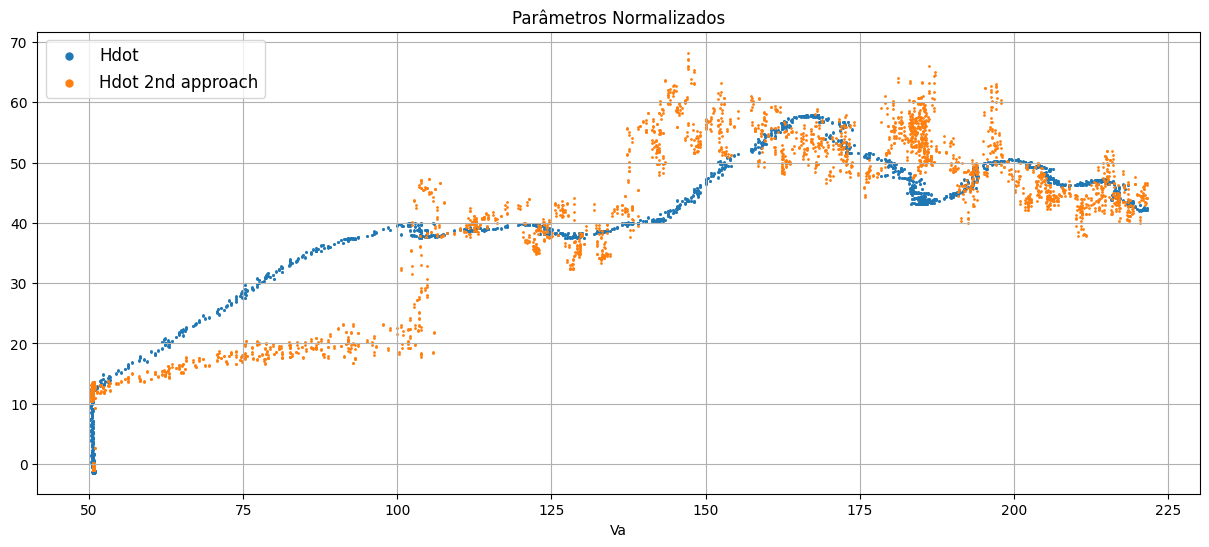

In [156]:
df = make_df('completo')
g = 9.81
t0 = 52050
t = 52150
# t0 = 4e4
# t = 9e4

df['Vsmooth'] = savgol_filter(
    df['Va']
    , window_length=51, polyorder=6)

n=1001
grau=3
T = 1/32
df['Vdot'] = savgol_filter(
    df['Va']
    , window_length=n, polyorder=grau, deriv=1, delta=T)

df['hdot'] = savgol_filter(
    df['Zp']
     , window_length=n, polyorder=grau, deriv=1, delta=T) 

df['Hdot'] = df['hdot'] + df['Vsmooth']*df['Vdot']/g

df['Hdot_2nd_approach'] = (df['NX']*np.cos(np.radians(df['Alfa'])) - df['NZ']*np.sin(np.radians(df['Alfa'])))*df['Va']

plt.figure(figsize=(15, 6))
eixo_x = 'Va'
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Va']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Va']).max(),
#     s=1, label='Va'
# )
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vsmooth']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vsmooth']).max(),
#     s=1, label='Vsmooth'
# )
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot']).max(),
#     s=1, label='Vdot'
# )
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot']).max(),
#     s=1, label='Hdot'
# )
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Zp']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Zp']).max(),
#     s=1, label='Zp'
# )
# plt.scatter(
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
#     df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_2nd_approach']/abs(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_2nd_approach']).max(),
#     s=1, label='Hdot 2nd approach'
# )
plt.scatter(
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot'],
    s=1, label='Hdot'
)
plt.scatter(
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_2nd_approach'],
    s=1, label='Hdot 2nd approach'
)
plt.xlabel(eixo_x)
plt.title('Parâmetros Normalizados')
plt.grid()
plt.legend(fontsize=12, markerscale=5)
# plt.xlim(52370,52500)
# plt.ylim(-0.2, 1)
plt.show()

# print(df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot'].mean())
# k=100
# v = df.loc[(df['TEMPO_SAD']>t) & (df['TEMPO_SAD']<t+k), 'Va'].values[0]
# v0 = df.loc[(df['TEMPO_SAD'] > t0) & (df['TEMPO_SAD']<t0+k), 'Va'].values[0]
# delta_v = v - v0
# delta_t = t - t0
# a = delta_v / delta_t
# print(a)

In [6]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [7]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [8]:
def build_model(features1, features2):  
    # 1. Definição das Entradas
    input_dim1 = len(features1)
    input_x1 = layers.Input(shape=(input_dim1,), name='Entrada_X1')
    input_dim2 = len(features2)
    input_x2 = layers.Input(shape=(input_dim2,), name='Entrada_X2')

    # 2. Rede Neural para X1 (NN1 -> Z1)
    x1 = layers.Dense(64, activation='relu')(input_x1)
    z1 = layers.Dense(1, name='Z1')(x1) # Resultado Z1

    # 3. Rede Neural para X2 (NN2 -> Z2)
    x2 = layers.Dense(64, activation='relu')(input_x2)
    z2 = layers.Dense(1, name='Z2')(x2) # Resultado Z2
    
    # 4. Saída: operação de Subtração (Z1 - Z2)
    output = layers.Subtract(name = 'Saida_Y')([z1, z2])

    # 5. Definição do Modelo
    model = Model(inputs=[input_x1, input_x2], outputs=output)

    # Compilação
    model.compile(optimizer='adam', loss='mse')

    return model

In [9]:
def train_model(df, features1, features2, targets, model, hyperparameters):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    X1_train, X1_val = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience']
    )

    training_history = model.fit(
        [X1_train, X2_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val], Y_val),
        verbose=1
    )

    return model, training_history

In [10]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets):
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    model = build_model(features1, features2)

    model, training_history = train_model(df, features1, features2, targets, model, hyperparameters)
    # training_history = 'mock'
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [11]:
def evaluate(model, df, features1, features2, targets, scaler_y):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    X_test = [
        np.array(df.loc[df['type'] == 'test', features1_scaled]).astype(np.float32),
        np.array(df.loc[df['type'] == 'test', features2_scaled]).astype(np.float32)                
    ]
    
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)

    for item in targets:
        df[item + '_pred'] = None

    for i, item in enumerate(targets):
        df.loc[df['type'] == 'test', item + '_pred'] = pred[:, i]

    real = np.array(df.loc[df['type'] == 'test', targets]).astype(np.float32)

    with np.errstate(divide='ignore', invalid='ignore'):
        erro = np.where(np.abs(real) > 1e-6, (pred - real) * 100 / real, np.nan)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)
    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }
    
    return results

In [12]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 60,
            'camadas_ocultas': 8,
            'activation': 'relu',
            'dropout': 0.0
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 120,
            'batch_size': 64,
            'patience': 5
        }
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results = evaluate(model, df, features1, features2, targets, scaler_y)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}'], dot_size, label=f'{item} Real')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}_pred'], dot_size, label=f'{item} Predito')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Erro médio: {results["avg_error"][i]:.2f}%')
        axs[2*i+1].scatter(df.loc[df['type'] == 'test']['No. OBS.'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()
    plt.savefig(f'figures/{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

Linhas removidas por NaN: 4 de 42493
=== NaN por coluna (colunas relevantes) ===
Va                    0
Zp                    0
Zp_ref                0
deltaZ                0
Vcorr                 0
Hdot_V                0
Mach                  0
CL                    0
N1_over_sqrt_theta    0
W                     0
dtype: int64

=== Valores negativos dentro da raiz ===
Negativos: 0 de 42489
Min valor dentro da raiz: 18050.1715

=== Estatísticas do Hdot_V ===
count    42489.000000
mean         0.078680
std          0.985086
min        -11.036678
25%          0.000000
50%          0.000000
75%          0.049927
max         12.457695
Name: Hdot_V, dtype: float64
Index(['TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K',
       'T', 'No. OBS.', 'h', 'Z', 'a1', 'a2', 'Pa', 'Rho', 'theta', 'Zp_ref',
       'deltaZ', 'Vcorr', 'Hdot_V', 'N1_over_sqrt_theta', 'delta',
       'T_over_delta', 'D', 'D_over_delta', 'faixa_altitude'],
      dtype='str')


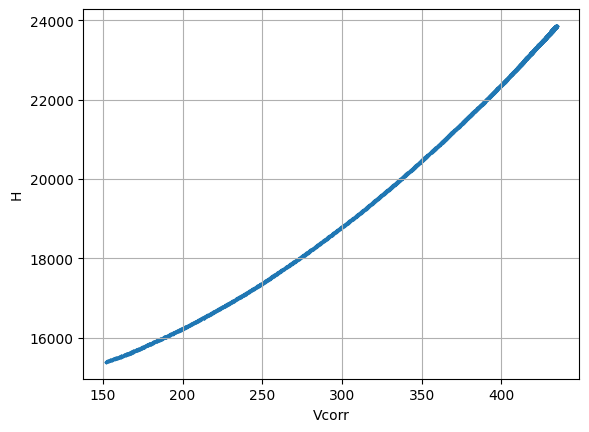

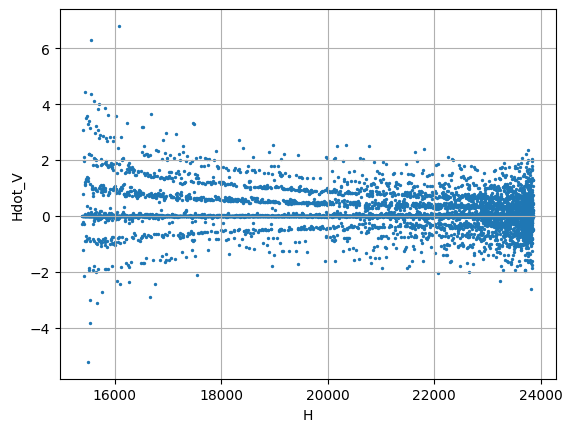

In [15]:
df = make_df('aceleracao_nivelada')

print("=== NaN por coluna (colunas relevantes) ===")
cols_check = ['Va', 'Zp', 'Zp_ref', 'deltaZ', 'Vcorr', 'Hdot_V', 'Mach', 'CL', 'N1_over_sqrt_theta', 'W']
print(df[cols_check].isna().sum())

print("\n=== Valores negativos dentro da raiz ===")
arg_raiz = df['Va']**2 + 2*9.81*df['deltaZ']
print(f"Negativos: {(arg_raiz < 0).sum()} de {len(arg_raiz)}")
print(f"Min valor dentro da raiz: {arg_raiz.min():.4f}")

print("\n=== Estatísticas do Hdot_V ===")
print(df['Hdot_V'].describe())

print(df.keys())

df['H'] = df['Zp_ref']*df['theta'] + df['Vcorr']**2/(2*9.81)

# plt.figure(figsize=(15, 6))
plt.scatter(df.loc[df['h'] == 150, 'Vcorr'],
             df.loc[df['h'] == 150, 'H'],
             s=2)
plt.xlabel('Vcorr')
plt.ylabel('H')
plt.grid()
plt.show()


plt.scatter(
    df.loc[df['h'] == 150, 'H'],
    df.loc[df['h'] == 150, 'Hdot_V'],
    s=2
)
plt.xlabel('H')
plt.ylabel('Hdot_V')
plt.grid()
plt.show()

Linhas removidas por NaN: 4 de 42493
Epoch 1/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0176 - val_loss: 9.9330e-04
Epoch 2/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 925us/step - loss: 0.0021 - val_loss: 9.3842e-04
Epoch 3/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 966us/step - loss: 0.0021 - val_loss: 7.0674e-04
Epoch 4/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 946us/step - loss: 0.0021 - val_loss: 9.8247e-04
Epoch 5/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 940us/step - loss: 0.0021 - val_loss: 7.5844e-04
Epoch 6/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 929us/step - loss: 0.0021 - val_loss: 7.4976e-04
Epoch 7/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 931us/step - loss: 0.0021 - val_loss: 0.0012
Epoch 8/120
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 907us/step - loss: 0.0021 - val_loss: 9.0078e-04
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 955us/step


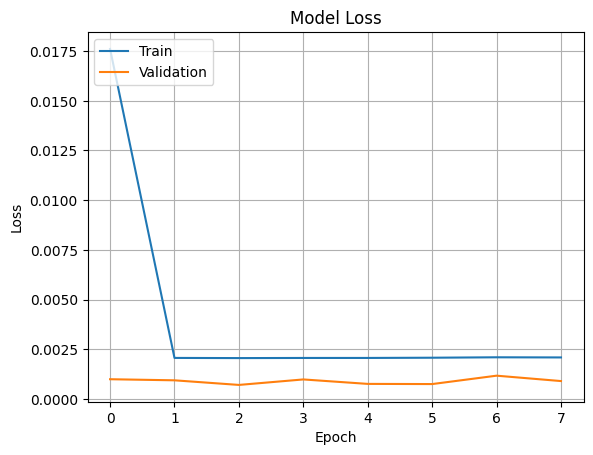

C:\Users\ymarc\AppData\Local\Temp\ipykernel_32000\2269238032.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


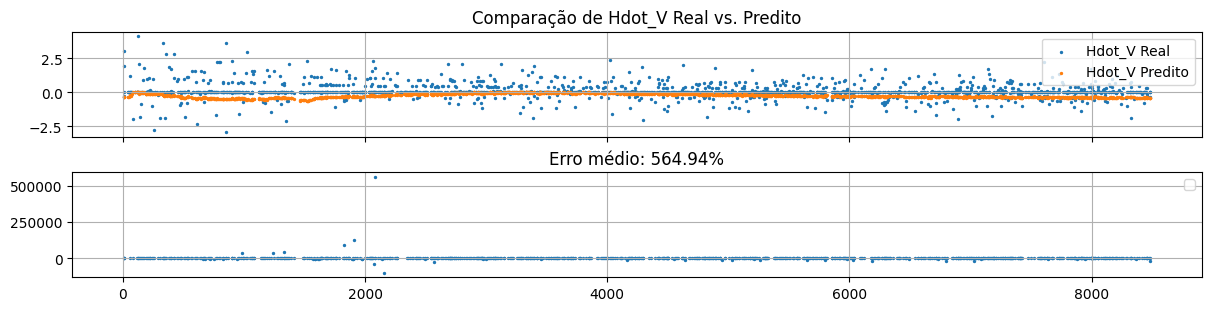

In [265]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='aceleracao_nivelada',
    features1=['Mach', 'N1_over_sqrt_theta', 'W'],
    features2=['Mach', 'CL', 'W'],
    targets=['Hdot_V']
)

C:\Users\ymarc\AppData\Local\Temp\ipykernel_32000\1109921713.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


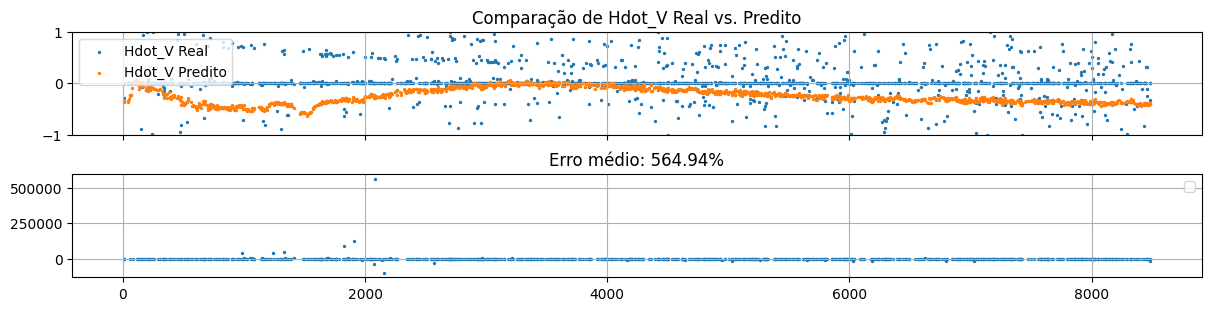

In [266]:
_, axs = plt.subplots(
    2 * len(['Hdot_V']),
    1,
    sharex=True,
    figsize=(12, 3 * len(['Hdot_V'])),
    constrained_layout=True
)
axs = axs.flatten()
dot_size = 2
for i, item in enumerate(['Hdot_V']):
    axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
    axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}'], dot_size, label=f'{item} Real')
    axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}_pred'], dot_size, label=f'{item} Predito')
    axs[2*i].legend()
    axs[2*i].grid()
    axs[2*i].set_ylim(-1, 1)

    axs[2*i+1].set_title(f'Erro médio: {results["avg_error"][i]:.2f}%')
    axs[2*i+1].scatter(df.loc[df['type'] == 'test']['No. OBS.'], results["rel_error"][:,i], dot_size)
    axs[2*i+1].legend()
    axs[2*i+1].grid()
# plt.xlim(1000.2000)
plt.show()